(sec-1-2)=
# 1.2 The Bioelectric Origin of Signals

Every ECG trace begins with ions crossing the membranes of heart muscle cells. Each cell keeps a voltage of about −90 mV across its membrane at rest, loses it in a fraction of a millisecond when it is excited, and recovers it a few hundred milliseconds later. Millions of cells doing this in an orderly sequence produce currents that spread through the tissues of the chest, and the electrodes on the skin pick up a faint echo of them: a millivolt, filtered and blurred by several centimeters of tissue. The same story, with neurons instead of cardiomyocytes and a skull in the way, explains the EEG, and with muscle fibers it explains the EMG.

I think it pays to understand this chain before processing any bioelectric signal, because it explains why the signals are so small, why they look smooth even though the underlying events are sharp, and why the same heartbeat looks different in different ECG leads. In this section we derive the Nernst equation from the physics of diffusion and drift, extend it to the Goldman–Hodgkin–Katz equation for the resting potential, simulate the Hodgkin–Huxley model of the action potential, and finally follow the currents into the body to see how a source inside the chest becomes a potential on its surface.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from scipy.special import exprel

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)

R_GAS = 8.314          # J/(mol K)
FARADAY = 96485.0      # C/mol
T_BODY = 310.15        # K (37 °C)

(sec-1-2-1)=
## 1.2.1 The Membrane and the Ions on Either Side

A cell is enclosed by a lipid bilayer about 5 nm thick. The lipid core does not let ions through, so the membrane behaves electrically like a thin insulator separating two conducting salt solutions, in other words like a capacitor, with a capacitance of about 1 µF per square centimeter. Ions can cross only through specialized proteins. **Ion channels** are pores that open and close and that are selective, letting through mostly Na⁺, or mostly K⁺, and so on. **Pumps** spend metabolic energy to move ions against their gradients; the most important is the Na⁺/K⁺-ATPase, which exports three Na⁺ ions and imports two K⁺ ions for every molecule of ATP it consumes.

The pumps' long-term work is a set of concentration differences between the inside and the outside of the cell. Representative values for a mammalian cell are listed below {cite:p}`plonsey2007,malmivuo1995`. Different cell types and different textbooks quote values that differ by a few millimoles per liter, but the pattern is always the same: potassium is concentrated inside, sodium and chloride outside, and free calcium is kept at a tiny intracellular concentration.

In [2]:
ions = pd.DataFrame({
    "ion": ["K+", "Na+", "Cl-", "Ca2+"],
    "z": [1, 1, -1, 2],
    "inside (mM)": [140.0, 12.0, 7.0, 0.0001],
    "outside (mM)": [5.0, 145.0, 110.0, 2.0],
}).set_index("ion")
ions["outside / inside"] = ions["outside (mM)"] / ions["inside (mM)"]
ions

,z,inside (mM),outside (mM),outside / inside
ion,,,,
K+,1,140.0000,5.0,0.035714
Na+,1,12.0000,145.0,12.083333
Cl-,-1,7.0000,110.0,15.714286
Ca2+,2,0.0001,2.0,20000.000000


A concentration difference alone does not produce a voltage. What produces it is the combination of a concentration difference and a membrane that lets one ion through more easily than the others. The next subsection makes this precise.

(sec-1-2-2)=
## 1.2.2 The Nernst Equation

Imagine a membrane permeable only to K⁺. Potassium ions diffuse outward, down their concentration gradient. Each ion that leaves carries a positive charge with it and leaves an unbalanced negative charge behind, so the inside becomes negative. The growing electric field pulls K⁺ back in. Equilibrium is reached when the electrical pull exactly balances the diffusive push, and the voltage at which that happens is the **equilibrium** or **Nernst potential** of potassium. Remarkably few ions need to move to set it up; the bulk concentrations are practically unchanged.

To derive it, we write down the two contributions to the flux $J$ of one ion species (in mol per square meter per second) across the membrane, along the coordinate $x$ that runs from the inside ($x = 0$) to the outside ($x = d$).

**Step 1: diffusion.** Fick's law states that particles flow from high to low concentration at a rate proportional to the concentration gradient,

$$
J_\text{diff} = -D\,\frac{dc}{dx},
$$

where $c(x)$ is the concentration and $D$ the diffusion coefficient.

**Step 2: electrical drift.** An ion of valence $z$ in an electric potential $\varphi(x)$ feels a force; per mole of ions the force is $-zF\,d\varphi/dx$, where $F$ is Faraday's constant (the charge of one mole of elementary charges). The ions drift with a velocity proportional to this force, $v = \bar{u}\,(-zF\,d\varphi/dx)$, where $\bar{u}$ is their molar mobility. The flux is concentration times velocity, $J_\text{drift} = c\,v$. Einstein's relation links mobility to diffusion, $D = \bar{u}RT$, with $R$ the gas constant and $T$ the absolute temperature, so

$$
J_\text{drift} = -\frac{D\,zF}{RT}\,c\,\frac{d\varphi}{dx}.
$$

**Step 3: add the two.** The total flux is the **Nernst–Planck equation**,

(eq-1-1)=
\begin{equation*}
J = -D\left(\frac{dc}{dx} + \frac{zF}{RT}\,c\,\frac{d\varphi}{dx}\right). \tag{1.1}
\end{equation*}

**Step 4: impose equilibrium.** At equilibrium there is no net flux, $J = 0$. Since $D \neq 0$, the bracket must vanish, and dividing by $c$ separates the variables:

$$
\frac{1}{c}\,\frac{dc}{dx} = -\frac{zF}{RT}\,\frac{d\varphi}{dx}.
$$

**Step 5: integrate across the membrane.** The left side is the derivative of $\ln c$. Integrating both sides from the inside ($c = c_i$, $\varphi = \varphi_i$) to the outside ($c = c_o$, $\varphi = \varphi_o$),

$$
\ln c_o - \ln c_i = -\frac{zF}{RT}\,(\varphi_o - \varphi_i).
$$

**Step 6: solve for the membrane potential.** Physiologists define the membrane potential as inside minus outside, $V_m = \varphi_i - \varphi_o$. Rearranging gives the **Nernst equation**

(eq-1-2)=
\begin{equation*}
E = \frac{RT}{zF}\,\ln\frac{c_o}{c_i}. \tag{1.2}
\end{equation*}

Notice what has disappeared. The diffusion coefficient, the thickness of the membrane and the shape of the potential profile inside it have all dropped out; only the concentration ratio and the valence remain. At body temperature $RT/F = 26.73$ mV, and since $\ln x = \ln 10 \cdot \log_{10} x$, the Nernst potential of a monovalent ion changes by $26.73 \times 2.303 = 61.5$ mV for every tenfold change in the concentration ratio.

**Example 1.2.1.** Compute the potassium equilibrium potential at 37 °C.

With $z = 1$, $c_o = 5$ mM and $c_i = 140$ mM,

$$
E_K = 26.73\ \text{mV} \times \ln\frac{5}{140} = 26.73\ \text{mV} \times (-3.332) = -89.1\ \text{mV}.
$$

The inside must be about 89 mV negative to hold potassium in. The code below repeats the calculation for all four ions.

In [3]:
def nernst(c_out, c_in, z, T=T_BODY):
    """Equilibrium potential (mV) of an ion with valence z, equation (1.2)."""
    return 1000 * R_GAS * T / (z * FARADAY) * np.log(c_out / c_in)


print(f"RT/F at 37 °C = {1000 * R_GAS * T_BODY / FARADAY:.2f} mV")
ions["E (mV)"] = nernst(ions["outside (mM)"], ions["inside (mM)"], ions["z"]).round(1)
ions[["z", "outside / inside", "E (mV)"]]

RT/F at 37 °C = 26.73 mV


,z,outside / inside,E (mV)
ion,,,
K+,1,0.035714,-89.1
Na+,1,12.083333,66.6
Cl-,-1,15.714286,-73.6
Ca2+,2,20000.000000,132.3


Potassium sits near −89 mV, sodium near +67 mV, chloride near −74 mV and calcium far out at about +132 mV, the large value coming from its enormous concentration ratio partly offset by its double charge.

We can check that the result really is independent of what happens inside the membrane. The next cell integrates the equilibrium condition of Step 4 numerically, $dc/dx = -(zF/RT)\,c\,d\varphi/dx$, across a 5-nm membrane with a deliberately strange, nonlinear potential profile whose end points differ by $E_K$. If the derivation is right, the concentration should arrive at the outer face at exactly 5 mM, whatever the profile looks like in between.

In [4]:
d_mem = 5e-9                                   # membrane thickness (m)
E_K = nernst(5.0, 140.0, 1) / 1000             # V


def phi(x):
    """An arbitrary potential profile (V) with phi(0) - phi(d) = E_K."""
    s = x / d_mem
    return E_K * (1 - s) + 0.03 * np.sin(np.pi * s) ** 2 * np.cos(3 * s)


def dphi_dx(x, h=1e-13):
    return (phi(x + h) - phi(x - h)) / (2 * h)


def zero_flux(x, c, z=1):
    return -z * FARADAY / (R_GAS * T_BODY) * c * dphi_dx(x)


sol = solve_ivp(zero_flux, (0, d_mem), [140.0], rtol=1e-10, atol=1e-12)
print(f"Concentration reached at the outer face: {sol.y[0, -1]:.4f} mM  (expected 5 mM)")

Concentration reached at the outer face: 5.0000 mM  (expected 5 mM)


(sec-1-2-3)=
## 1.2.3 The Goldman–Hodgkin–Katz Equation

A real membrane is permeable to several ions at once, and at rest no single ion is at equilibrium. Potassium leaks out, sodium leaks in, and the pumps restore both. The membrane potential settles where the *total* electric current through the membrane is zero, a steady state rather than an equilibrium, and its value lies somewhere between the Nernst potentials of the permeant ions, pulled most strongly toward the ion with the highest permeability.

{cite:t}`goldman1943` found the formula by assuming that the electric field inside the membrane is uniform, the **constant-field assumption**. I find the derivation worth following once, because it is a nice application of the integrating factor method and it shows exactly where each term of the final formula comes from.

**Step 1: write the Nernst–Planck equation with a constant field.** If the potential falls linearly from $\varphi_i$ to $\varphi_o$ over the thickness $d$, then $d\varphi/dx = -V_m/d$. Defining the dimensionless voltage $u = zFV_m/(RT)$, equation (1.1) becomes

$$
\frac{dc}{dx} - \frac{u}{d}\,c = -\frac{J}{D}.
$$

**Step 2: solve the linear ODE.** In steady state the flux $J$ is the same at every $x$, so this is a first-order linear equation with a constant right-hand side. Multiplying by the integrating factor $e^{-ux/d}$ turns the left side into an exact derivative,

$$
\frac{d}{dx}\left(c\,e^{-ux/d}\right) = -\frac{J}{D}\,e^{-ux/d}.
$$

**Step 3: integrate across the membrane.** Integrating from $0$ to $d$, and writing the concentrations just inside the two faces of the membrane as $\beta c_i$ and $\beta c_o$, where $\beta$ is a partition coefficient between water and membrane,

$$
\beta\left(c_o\,e^{-u} - c_i\right) = -\frac{J}{D}\cdot\frac{d}{u}\left(1 - e^{-u}\right).
$$

Solving for $J$ and collecting $\beta D/d$ into a single **permeability** $P$ (in m/s) gives the GHK flux equation

(eq-1-3)=
\begin{equation*}
J = P\,u\,\frac{c_i - c_o\,e^{-u}}{1 - e^{-u}}. \tag{1.3}
\end{equation*}

**Step 4: sum the currents of K⁺, Na⁺ and Cl⁻.** Each flux carries the current $zFJ$. For the cations $z = +1$ and $u = v \equiv FV_m/(RT)$. For chloride $z = -1$, so $u = -v$; multiplying numerator and denominator of (1.3) by $e^{-v}$ and including the factor $z = -1$ in the current shows that its contribution is $F P_\text{Cl}\, v\,(c_{o,\text{Cl}} - c_{i,\text{Cl}}\,e^{-v})/(1 - e^{-v})$. All three currents therefore share the factor $Fv/(1 - e^{-v})$, and setting the total to zero leaves

$$
P_K\left([K]_i - [K]_o e^{-v}\right) + P_\text{Na}\left([Na]_i - [Na]_o e^{-v}\right) + P_\text{Cl}\left([Cl]_o - [Cl]_i e^{-v}\right) = 0 .
$$

**Step 5: solve for $V_m$.** Moving the terms with $e^{-v}$ to one side, dividing, and taking the logarithm gives the **Goldman–Hodgkin–Katz (GHK) voltage equation**

(eq-1-4)=
\begin{equation*}
V_m = \frac{RT}{F}\,\ln\frac{P_K[K]_o + P_\text{Na}[Na]_o + P_\text{Cl}[Cl]_i}{P_K[K]_i + P_\text{Na}[Na]_i + P_\text{Cl}[Cl]_o}. \tag{1.4}
\end{equation*}

Each concentration is weighted by the permeability of its ion, so the more permeable an ion, the more the potential is pulled toward its Nernst potential. Chloride appears "upside down" (inside concentration in the numerator) because it carries a negative charge. And if one permeability dominates, for example $P_K \gg P_\text{Na}, P_\text{Cl}$, the other terms vanish and (1.4) reduces to the Nernst equation for that ion. Only the *ratios* of the permeabilities matter, since a common factor cancels between numerator and denominator.

**Example 1.2.2.** With the classic resting permeability ratios $P_K : P_\text{Na} : P_\text{Cl} = 1 : 0.04 : 0.45$ and the concentrations of Section 1.2.1,

$$
V_m = 26.73\ \text{mV} \times \ln\frac{5 + 0.04 \cdot 145 + 0.45 \cdot 7}{140 + 0.04 \cdot 12 + 0.45 \cdot 110}
= 26.73\ \text{mV} \times \ln\frac{13.95}{189.98} = -69.8\ \text{mV}.
$$

The result lies 19 mV above $E_K$, dragged upward by the small sodium leak. To check it, we can avoid equation (1.4) altogether: we write the total membrane current from the flux equation (1.3) as a function of $V_m$ and find its zero numerically.

In [5]:
P = {"K+": 1.0, "Na+": 0.04, "Cl-": 0.45}            # relative permeabilities
conc = ions[["inside (mM)", "outside (mM)", "z"]]


def ghk_voltage(K_o=5.0, T=T_BODY):
    """Resting potential (mV) from the GHK voltage equation (1.4)."""
    num = P["K+"] * K_o + P["Na+"] * conc.loc["Na+", "outside (mM)"] + P["Cl-"] * conc.loc["Cl-", "inside (mM)"]
    den = (P["K+"] * conc.loc["K+", "inside (mM)"] + P["Na+"] * conc.loc["Na+", "inside (mM)"]
           + P["Cl-"] * conc.loc["Cl-", "outside (mM)"])
    return 1000 * R_GAS * T / FARADAY * np.log(num / den)


def total_current(V_mV, T=T_BODY):
    """Net GHK current (arbitrary units) at membrane potential V_mV, summed from equation (1.3)."""
    total = 0.0
    for ion, p in P.items():
        c_i, c_o, z = conc.loc[ion]
        u = z * FARADAY * V_mV / 1000 / (R_GAS * T)
        total += z * p * u * (c_i - c_o * np.exp(-u)) / (1 - np.exp(-u))
    return total


V_formula = ghk_voltage()
V_root = brentq(total_current, -100, -20)
print(f"GHK equation (1.4)          : {V_formula:.2f} mV")
print(f"Zero of the summed currents : {V_root:.2f} mV")

GHK equation (1.4)          : -69.79 mV
Zero of the summed currents : -69.79 mV


### Sensitivity to extracellular potassium

Because potassium dominates the resting permeability, the resting potential follows the extracellular potassium concentration closely. This is not an academic point. Serum potassium is normally kept between about 3.5 and 5 mmol/L, and **hyperkalemia**, an excess of potassium in the blood (for example in kidney failure), depolarizes every excitable cell in the body. In the heart this changes conduction and repolarization, which shows up on the ECG as tall, peaked T waves and, at higher levels, as widened QRS complexes and dangerous arrhythmias. Cardiac surgeons exploit the same mechanism when they stop the heart with a high-potassium cardioplegic solution.

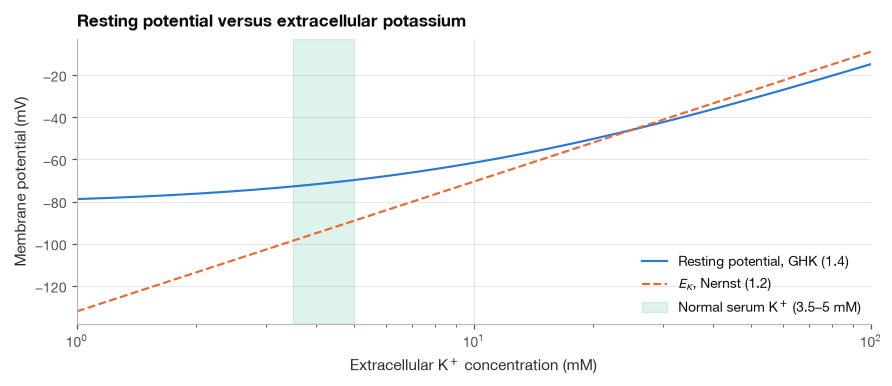

[K+]o =  3.0 mM :  V_rest =  -73.9 mV,  E_K = -102.7 mV
[K+]o =  5.0 mM :  V_rest =  -69.8 mV,  E_K =  -89.1 mV
[K+]o =  7.0 mM :  V_rest =  -66.2 mV,  E_K =  -80.1 mV
[K+]o = 10.0 mM :  V_rest =  -61.6 mV,  E_K =  -70.5 mV


In [6]:
K_out = np.logspace(0, 2, 300)                    # 1 to 100 mM
V_rest = ghk_voltage(K_out)
E_K_curve = nernst(K_out, 140.0, 1)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogx(K_out, V_rest, color=C[0], label="Resting potential, GHK (1.4)")
ax.semilogx(K_out, E_K_curve, color=C[1], ls="--", label="$E_K$, Nernst (1.2)")
ax.axvspan(3.5, 5.0, color=C[2], alpha=0.15, label="Normal serum K$^+$ (3.5–5 mM)")
ax.set(xlabel="Extracellular K$^+$ concentration (mM)", ylabel="Membrane potential (mV)",
       title="Resting potential versus extracellular potassium", xlim=(1, 100))
ax.legend(loc="lower right")
plt.show()

for k in (3.0, 5.0, 7.0, 10.0):
    print(f"[K+]o = {k:4.1f} mM :  V_rest = {ghk_voltage(k):6.1f} mV,  E_K = {nernst(k, 140.0, 1):6.1f} mV")

At high extracellular potassium the two curves merge: potassium terms dominate both numerator and denominator of (1.4), and the membrane behaves like a potassium electrode with a slope of 61.5 mV per decade. At low potassium the sodium and chloride terms become comparable to the shrinking $P_K[K]_o$, and the resting potential no longer follows $E_K$ down. Raising $[K]_o$ from 5 to 7 mM, a moderate hyperkalemia, depolarizes the model membrane by about 4 mV.

(sec-1-2-4)=
## 1.2.4 The Action Potential: The Hodgkin–Huxley Model

The resting potential is only the starting point. Excitable cells can change their permeabilities within a fraction of a millisecond, and the resulting **action potential** is the elementary event behind every bioelectric signal in this book. {cite:t}`hodgkin1952` described it quantitatively for the squid giant axon in a model that remains the template for every later model of excitable membranes, including those of cardiac cells.

### The membrane equation

Electrically, a patch of membrane is a capacitor $C_m$ in parallel with three conducting branches: a sodium branch, a potassium branch and a small "leak" branch that lumps together everything else. Each branch is a conductance in series with a battery equal to the Nernst potential of its ion, so the current through it is the conductance times the distance from equilibrium, for example $I_\text{Na} = g_\text{Na}(V - E_\text{Na})$. Kirchhoff's current law says that an externally applied current $I_\text{ext}$ must either charge the capacitor or flow through one of the branches:

(eq-1-5)=
\begin{equation*}
C_m\,\frac{dV}{dt} = I_\text{ext} - \bar{g}_\text{Na}\,m^3 h\,(V - E_\text{Na}) - \bar{g}_K\,n^4\,(V - E_K) - g_L\,(V - E_L). \tag{1.5}
\end{equation*}

The bars denote maximal conductances. Hodgkin and Huxley's insight was to write the time-varying conductances as these maximal values multiplied by powers of three **gating variables** $m$, $h$ and $n$, each between 0 and 1. Sodium channels open when $m$ (activation) is large and close when $h$ (inactivation) is small; potassium channels open when $n$ is large.

### Gating kinetics

Each gating variable obeys first-order kinetics. A gate opens at a voltage-dependent rate $\alpha(V)$ and closes at rate $\beta(V)$, so for the fraction $x$ of open gates

(eq-1-6)=
\begin{equation*}
\frac{dx}{dt} = \alpha_x(V)\,(1 - x) - \beta_x(V)\,x, \qquad x \in \{m, h, n\}. \tag{1.6}
\end{equation*}

Collecting the terms in $x$ makes the behavior easier to see:

(eq-1-7)=
\begin{equation*}
\frac{dx}{dt} = \alpha_x - (\alpha_x + \beta_x)\,x = \frac{x_\infty(V) - x}{\tau_x(V)}, \qquad
x_\infty = \frac{\alpha_x}{\alpha_x + \beta_x}, \quad \tau_x = \frac{1}{\alpha_x + \beta_x}. \tag{1.7}
\end{equation*}

At a fixed voltage, then, each gate relaxes exponentially toward its steady-state value $x_\infty(V)$ with time constant $\tau_x(V)$. The rate functions were fitted by Hodgkin and Huxley to voltage-clamp measurements. I use them here in the modern sign convention (inside minus outside, resting potential near −65 mV) with the classic squid-axon parameters at 6.3 °C: $\bar{g}_\text{Na} = 120$, $\bar{g}_K = 36$ and $g_L = 0.3$ mS/cm², $E_\text{Na} = 50$, $E_K = -77$ and $E_L = -54.4$ mV, and $C_m = 1$ µF/cm². Two of the rate functions have the form $a\,u/(1 - e^{-u})$, which is $0/0$ at $u = 0$; we evaluate it with SciPy's `exprel` function, which handles the limit exactly.

In [7]:
C_M = 1.0                                   # µF/cm²
G_NA, G_K, G_L = 120.0, 36.0, 0.3           # mS/cm²
E_NA, E_K_HH, E_L = 50.0, -77.0, -54.387    # mV


def rates(V):
    """Hodgkin-Huxley opening and closing rates (1/ms) at membrane potential V (mV)."""
    a_m = 1.0 / exprel(-(V + 40) / 10)      # = 0.1 (V + 40) / (1 - exp(-(V + 40)/10))
    b_m = 4.0 * np.exp(-(V + 65) / 18)
    a_h = 0.07 * np.exp(-(V + 65) / 20)
    b_h = 1.0 / (1 + np.exp(-(V + 35) / 10))
    a_n = 0.1 / exprel(-(V + 55) / 10)      # = 0.01 (V + 55) / (1 - exp(-(V + 55)/10))
    b_n = 0.125 * np.exp(-(V + 65) / 80)
    return a_m, b_m, a_h, b_h, a_n, b_n


def hh_derivatives(y, I_ext):
    """Right-hand side of equations (1.5)-(1.6) for the state y = (V, m, h, n)."""
    V, m, h, n = y
    a_m, b_m, a_h, b_h, a_n, b_n = rates(V)
    I_ion = G_NA * m**3 * h * (V - E_NA) + G_K * n**4 * (V - E_K_HH) + G_L * (V - E_L)
    return np.array([(I_ext - I_ion) / C_M,
                     a_m * (1 - m) - b_m * m,
                     a_h * (1 - h) - b_h * h,
                     a_n * (1 - n) - b_n * n])


V_axis = np.linspace(-100, 50, 301)
a_m, b_m, a_h, b_h, a_n, b_n = rates(V_axis)
gates = {"m": (a_m, b_m), "h": (a_h, b_h), "n": (a_n, b_n)}

V_REST = -65.0
y_rest = np.array([V_REST] + [a / (a + b) for a, b in (rates(V_REST)[i:i + 2] for i in (0, 2, 4))])
print("Resting state: V = {:.1f} mV, m = {:.4f}, h = {:.4f}, n = {:.4f}".format(*y_rest))

Resting state: V = -65.0 mV, m = 0.0529, h = 0.5961, n = 0.3177


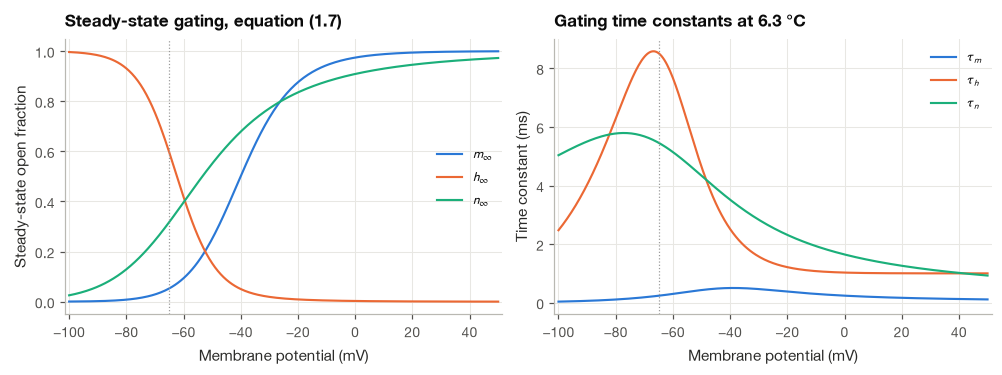

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for k, (name, (a, b)) in enumerate(gates.items()):
    axes[0].plot(V_axis, a / (a + b), color=C[k], label=f"${name}_\\infty$")
    axes[1].plot(V_axis, 1 / (a + b), color=C[k], label=f"$\\tau_{name}$")
for ax in axes:
    ax.axvline(V_REST, color="0.6", lw=0.8, ls=":")
axes[0].set(xlabel="Membrane potential (mV)", ylabel="Steady-state open fraction",
            title="Steady-state gating, equation (1.7)")
axes[1].set(xlabel="Membrane potential (mV)", ylabel="Time constant (ms)",
            title="Gating time constants at 6.3 °C")
axes[0].legend(loc="center right")
axes[1].legend(loc="upper right")
plt.show()

These two panels already contain the whole mechanism of the action potential. Depolarization raises $m_\infty$, and because $\tau_m$ is only a fraction of a millisecond, sodium channels open almost immediately. The same depolarization lowers $h_\infty$ and raises $n_\infty$, but $\tau_h$ and $\tau_n$ are several milliseconds, so sodium inactivation and potassium activation arrive late. There is a short window in which sodium current dominates, and that window is the action potential.

### Integrating the equations carefully

The four coupled equations (1.5)–(1.6) have no closed-form solution, so we integrate them numerically. I use two integrators and compare them. The first is SciPy's adaptive Runge–Kutta solver `solve_ivp` with tight tolerances. Because the stimulus current switches on and off abruptly, we integrate each constant-current segment separately so that the step-size control never has to straddle a discontinuity. The second is a fixed-step classical fourth-order Runge–Kutta (RK4) scheme with a step of 0.01 ms, written so that it advances many simulations with different stimuli at once; we need that speed for the threshold experiments in the next subsection.

In [9]:
def simulate_segments(segments, y0=y_rest, dt=0.01):
    """Integrate the HH model with solve_ivp over consecutive (duration_ms, current) segments."""
    t_all, y_all, t0, y = [], [], 0.0, np.asarray(y0, float)
    for duration, current in segments:
        sol = solve_ivp(lambda t, s: hh_derivatives(s, current), (t0, t0 + duration), y,
                        rtol=1e-8, atol=1e-10, max_step=0.05, dense_output=True)
        t_seg = np.arange(round(duration / dt)) * dt + t0
        t_all.append(t_seg)
        y_all.append(sol.sol(t_seg))
        y = sol.y[:, -1]                    # state at the end of the segment
        t0 += duration
    return np.concatenate(t_all), np.concatenate(y_all, axis=1)


def hh_rk4(I_ext, dt=0.01, y0=y_rest):
    """Fixed-step RK4 for many trials at once; I_ext has shape (n_steps, n_trials). Returns V."""
    y = np.repeat(np.asarray(y0, float)[:, None], I_ext.shape[1], axis=1)
    V = np.empty_like(I_ext)
    for k in range(I_ext.shape[0]):
        V[k] = y[0]
        I = I_ext[k]
        k1 = hh_derivatives(y, I)
        k2 = hh_derivatives(y + 0.5 * dt * k1, I)
        k3 = hh_derivatives(y + 0.5 * dt * k2, I)
        k4 = hh_derivatives(y + dt * k3, I)
        y = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return V


# a 1-ms, 10 µA/cm² pulse starting at t = 5 ms
t_ap, y_ap = simulate_segments([(5.0, 0.0), (1.0, 10.0), (24.0, 0.0)])
I_pulse = np.where((t_ap >= 5) & (t_ap < 6), 10.0, 0.0)[:, None]
V_rk4 = hh_rk4(I_pulse)[:, 0]

above_zero = t_ap[y_ap[0] > 0]
print(f"Peak of the action potential   : {y_ap[0].max():.2f} mV at t = {t_ap[y_ap[0].argmax()]:.2f} ms")
print(f"Most negative afterpotential   : {y_ap[0].min():.2f} mV")
print(f"Time spent above 0 mV          : {above_zero[-1] - above_zero[0]:.2f} ms")
print(f"Max |V_solve_ivp - V_RK4|      : {np.abs(y_ap[0] - V_rk4).max():.1e} mV")

Peak of the action potential   : 39.07 mV at t = 7.51 ms
Most negative afterpotential   : -76.17 mV
Time spent above 0 mV          : 1.12 ms
Max |V_solve_ivp - V_RK4|      : 1.1e-04 mV


The two integrators agree to about $10^{-4}$ mV over the whole action potential, so we can trust either of them. The figure shows the membrane potential together with the gating variables and the two conductances that they control.

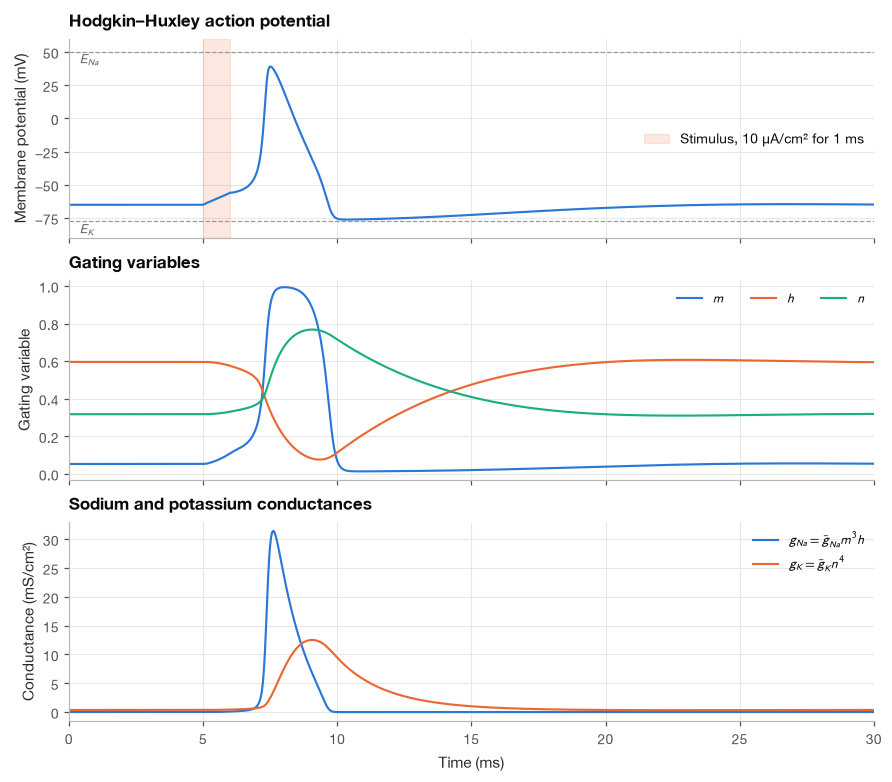

In [10]:
V, m, h, n = y_ap
g_na = G_NA * m**3 * h
g_k = G_K * n**4

fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
axes[0].plot(t_ap, V, color=C[0])
axes[0].axvspan(5, 6, color=C[1], alpha=0.15, label="Stimulus, 10 µA/cm² for 1 ms")
axes[0].axhline(E_NA, color="0.6", lw=0.8, ls="--")
axes[0].axhline(E_K_HH, color="0.6", lw=0.8, ls="--")
axes[0].text(0.4, E_NA - 9, "$E_{Na}$", fontsize=9, color="0.4")
axes[0].text(0.4, E_K_HH - 10, "$E_K$", fontsize=9, color="0.4")
axes[0].set(ylabel="Membrane potential (mV)", title="Hodgkin–Huxley action potential", ylim=(-90, 60))
axes[0].legend(loc="center right")

for k, (name, x) in enumerate(zip("mhn", (m, h, n))):
    axes[1].plot(t_ap, x, color=C[k], label=f"${name}$")
axes[1].set(ylabel="Gating variable", title="Gating variables", ylim=(-0.03, 1.03))
axes[1].legend(loc="upper right", ncols=3)

axes[2].plot(t_ap, g_na, color=C[0], label=r"$g_{Na} = \bar{g}_{Na} m^3 h$")
axes[2].plot(t_ap, g_k, color=C[1], label=r"$g_K = \bar{g}_K n^4$")
axes[2].set(xlabel="Time (ms)", ylabel="Conductance (mS/cm²)", title="Sodium and potassium conductances",
            xlim=(0, 30))
axes[2].legend(loc="upper right")
plt.show()

The sequence of events reads directly off the three panels. The stimulus pushes the membrane a few millivolts above rest; $m$ responds within a fraction of a millisecond, the sodium conductance rises, sodium ions rush in, and the depolarization feeds on itself until the potential approaches $E_\text{Na}$, peaking near +39 mV. Meanwhile $h$ falls and $n$ rises, more slowly. The sodium conductance collapses as the channels inactivate, the potassium conductance peaks about 1.5 ms later, and potassium efflux drives the potential back down, overshooting the resting value toward $E_K$ to about −76 mV before the gates relax to their resting state. The whole event in the squid axon at 6.3 °C spends only about 1.1 ms above 0 mV. Ventricular cells add a plateau carried by calcium currents and last 200–300 ms, which is why the ventricular repolarization (the T wave) appears so long after the QRS complex in the ECG.

(sec-1-2-5)=
## 1.2.5 Threshold and Refractoriness

Two properties of the action potential matter greatly for signal analysis. It is **all-or-none**: a stimulus either triggers a full action potential or almost nothing. And it is followed by a **refractory period** during which a second action potential is hard or impossible to trigger. The first property makes action potentials behave like discrete events; the second limits how fast excitable tissue can fire, and in the heart it is what prevents the ventricles from being re-excited before they have relaxed.

### Step 1: Find the threshold by bisection

A stimulus is "supra-threshold" if the membrane potential subsequently crosses 0 mV. We search for the smallest amplitude of a 1-ms pulse that does this, using bisection on many candidate amplitudes in parallel.

In [11]:
dt = 0.01
t_sim = np.arange(0, 40, dt)
on_first = (t_sim >= 5) & (t_sim < 6)


def count_spikes(V):
    """Number of upward crossings of 0 mV in each column of V."""
    return np.sum((V[:-1] < 0) & (V[1:] >= 0), axis=0)


lo, hi = np.array([0.0]), np.array([20.0])
for _ in range(25):
    mid = 0.5 * (lo + hi)
    fires = count_spikes(hh_rk4(np.outer(on_first, mid))) >= 1
    hi, lo = np.where(fires, mid, hi), np.where(fires, lo, mid)
threshold = hi[0]
print(f"Threshold for a 1-ms pulse: {threshold:.4f} µA/cm²")

Threshold for a 1-ms pulse: 6.9148 µA/cm²


### Step 2: Stimulate at and around threshold

With the threshold known, we stimulate at fixed fractions of it, and we also sweep the pulse amplitude from 0 to 15 µA/cm² and record the peak potential of each response.

In [12]:
factors = np.array([0.5, 0.9, 0.99, 1.01, 1.5])
V_thr = hh_rk4(np.outer(on_first, factors * threshold))

amplitudes = np.linspace(0, 15, 151)
V_sweep = hh_rk4(np.outer(on_first, amplitudes))
peak = V_sweep.max(axis=0)
print(f"Peak V for 0.99 x threshold: {V_thr[:, 2].max():6.1f} mV")
print(f"Peak V for 1.01 x threshold: {V_thr[:, 3].max():6.1f} mV")

Peak V for 0.99 x threshold:  -57.6 mV
Peak V for 1.01 x threshold:   34.7 mV


### Step 3: Probe the refractory period with a second pulse

We now deliver a conditioning pulse of 10 µA/cm² at $t = 5$ ms, followed by a test pulse at an interval $\Delta$ after it, and search, again by bisection, for the smallest test amplitude that produces a second spike. Amplitudes are searched up to 200 µA/cm², almost thirty times the resting threshold.

In [13]:
intervals = np.arange(4.0, 31.0, 1.0)                     # ms between pulse onsets


def two_pulse_current(test_amplitudes, first=10.0):
    """Stimulus matrix: a conditioning pulse at 5 ms and a test pulse after each interval."""
    I = np.zeros((t_sim.size, intervals.size))
    I[on_first, :] = first
    for j, delta in enumerate(intervals):
        I[(t_sim >= 5 + delta) & (t_sim < 6 + delta), j] += test_amplitudes[j]
    return I


lo, hi = np.zeros(intervals.size), np.full(intervals.size, 200.0)
for _ in range(14):
    mid = 0.5 * (lo + hi)
    fires = count_spikes(hh_rk4(two_pulse_current(mid))) >= 2
    hi, lo = np.where(fires, mid, hi), np.where(fires, lo, mid)
test_threshold = np.where(hi < 199.0, hi, np.nan)          # nan: no second spike up to 200 µA/cm²

V_pairs = hh_rk4(two_pulse_current(np.full(intervals.size, 10.0)))
print("No second spike at any amplitude for intervals up to "
      f"{intervals[np.isnan(test_threshold)].max():.0f} ms")
print(pd.DataFrame({"interval (ms)": intervals[3::3],
                    "test threshold (µA/cm²)": np.round(test_threshold[3::3], 2)}).to_string(index=False))

No second spike at any amplitude for intervals up to 6 ms
 interval (ms)  test threshold (µA/cm²)
           7.0                   101.25
          10.0                    30.62
          13.0                    13.94
          16.0                     7.68
          19.0                     5.87
          22.0                     6.18
          25.0                     6.92
          28.0                     7.17


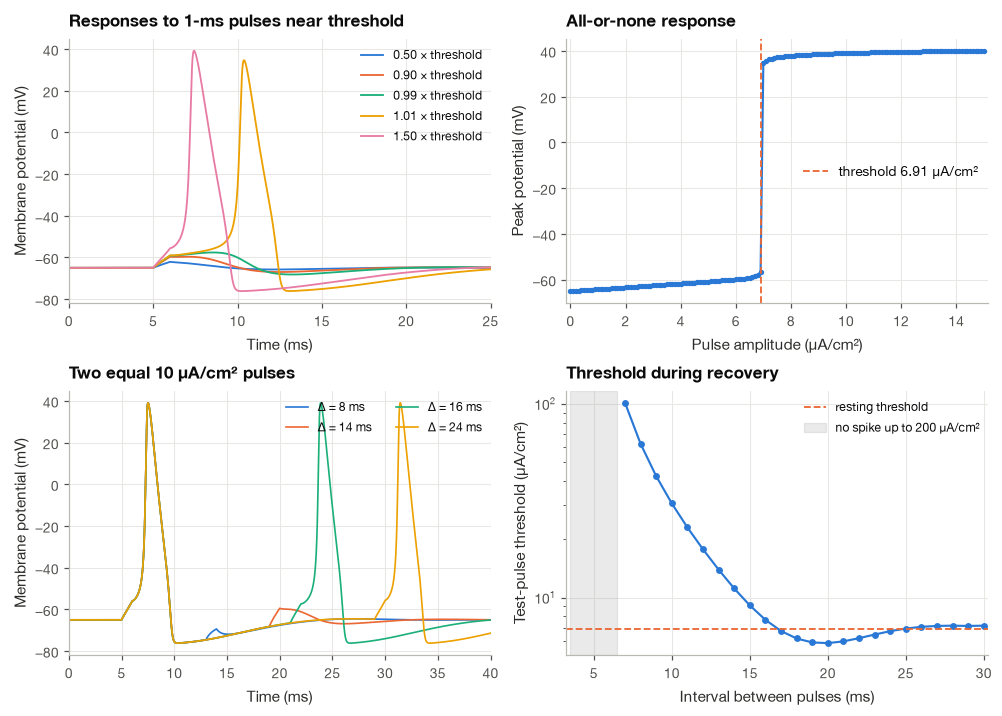

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
ax = axes[0, 0]
for k, f in enumerate(factors):
    ax.plot(t_sim, V_thr[:, k], color=C[k], lw=1.2, label=f"{f:.2f} × threshold")
ax.set(xlim=(0, 25), xlabel="Time (ms)", ylabel="Membrane potential (mV)",
       title="Responses to 1-ms pulses near threshold")
ax.legend(loc="upper right", fontsize=8)

ax = axes[0, 1]
ax.plot(amplitudes, peak, "-o", color=C[0], ms=2.5)
ax.axvline(threshold, color=C[1], ls="--", lw=1.2, label=f"threshold {threshold:.2f} µA/cm²")
ax.set(xlabel="Pulse amplitude (µA/cm²)", ylabel="Peak potential (mV)", title="All-or-none response")
ax.legend(loc="center right")

ax = axes[1, 0]
for k, delta in enumerate([8, 14, 16, 24]):
    j = np.flatnonzero(intervals == delta)[0]
    ax.plot(t_sim, V_pairs[:, j], color=C[k], lw=1.1, label=f"Δ = {delta} ms")
ax.set(xlim=(0, 40), xlabel="Time (ms)", ylabel="Membrane potential (mV)",
       title="Two equal 10 µA/cm² pulses")
ax.legend(loc="upper right", fontsize=8, ncols=2)

ax = axes[1, 1]
ax.plot(intervals, test_threshold, "-o", color=C[0], ms=3.5)
ax.axhline(threshold, color=C[1], ls="--", lw=1.2, label="resting threshold")
ax.axvspan(intervals[0] - 0.5, intervals[np.isnan(test_threshold)].max() + 0.5, color="0.6", alpha=0.2,
           label="no spike up to 200 µA/cm²")
ax.set(yscale="log", xlabel="Interval between pulses (ms)", ylabel="Test-pulse threshold (µA/cm²)",
       title="Threshold during recovery")
ax.legend(loc="upper right", fontsize=8)
plt.show()

The top row shows the all-or-none law. At 0.99 times threshold the membrane rises by about 7 mV and relaxes; at 1.01 times threshold it fires a full action potential, and the peak hardly grows as the stimulus is increased further. The threshold of about 6.9 µA/cm² for a 1-ms pulse is not a fixed voltage built into the model but the point at which the regenerative sodium current wins against the potassium and leak currents.

The bottom row shows refractoriness. For intervals of up to 6 ms, no test pulse up to 200 µA/cm² could produce a second spike: the sodium channels are still inactivated ($h$ is small) and the potassium conductance is high, an **absolute refractory period**. Beyond that, a second spike is possible but needs a stronger stimulus, and its peak is lower, the **relative refractory period**. With two equal 10 µA/cm² pulses, a second spike appears only once the interval reaches about 15 ms. Between roughly 17 and 25 ms the threshold even dips slightly below its resting value, because by then $h$ has recovered a little past its resting level while $n$ has not yet climbed back to its own. The squid axon at 6.3 °C is slow; mammalian neurons at body temperature recover within a few milliseconds, while ventricular myocytes stay refractory for most of their 250-ms action potential, a protective property that fails in some arrhythmias.

(sec-1-2-6)=
## 1.2.6 From Cells to the Body Surface: Volume Conduction

Action potentials happen at membranes, but electrodes sit on the skin. In between lies a **volume conductor**: tissues filled with salt water that carry the currents leaving active cells. To see what an electrode records, we need the potential that a current source produces in such a medium. I make three simplifications that are standard in a first treatment {cite:p}`malmivuo1995,plonsey2007`: the medium is infinite, it is homogeneous with a single conductivity $\sigma$ (about 0.2–0.5 S/m for soft tissue), and it is quasi-static, meaning that at physiological frequencies the potentials follow the sources instantaneously without capacitive or inductive delays.

### The monopole

Suppose a current $I$ is injected at a single point, for example at a patch of membrane where current flows out of a cell. In a homogeneous medium the current spreads out equally in all directions. **Step 1:** through a sphere of radius $r$ around the source the whole current $I$ must pass, so the current density there is $J(r) = I/(4\pi r^2)$. **Step 2:** Ohm's law in a conducting medium, $J = \sigma E$, gives the electric field $E(r) = I/(4\pi\sigma r^2)$, pointing radially outward. **Step 3:** the potential is the integral of the field from $r$ to infinity, where we set it to zero:

(eq-1-8)=
\begin{equation*}
\varphi(r) = \int_r^\infty \frac{I}{4\pi\sigma r'^2}\,dr' = \frac{I}{4\pi\sigma}\left[-\frac{1}{r'}\right]_r^\infty = \frac{I}{4\pi\sigma r}. \tag{1.8}
\end{equation*}

### The dipole

Current that leaves a cell at one place must re-enter it somewhere nearby, so sources come with sinks. The simplest such pair is a **current dipole**: a source $+I$ at $(0, 0, d/2)$ and a sink $-I$ at $(0, 0, -d/2)$. Because the medium is linear, the potentials of the two add (superposition), and with $r_\pm$ the distances from the observation point to the source and the sink,

$$
\varphi = \frac{I}{4\pi\sigma}\left(\frac{1}{r_+} - \frac{1}{r_-}\right).
$$

Far from the pair, at a distance $r \gg d$ and an angle $\theta$ from the dipole axis, the law of cosines gives $r_+^2 = r^2 - r d\cos\theta + d^2/4$. Factoring out $r^2$ and using the binomial approximation $(1 + \varepsilon)^{-1/2} \approx 1 - \varepsilon/2$ for small $\varepsilon$,

$$
\frac{1}{r_+} = \frac{1}{r}\left(1 - \frac{d}{r}\cos\theta + \frac{d^2}{4r^2}\right)^{-1/2} \approx \frac{1}{r}\left(1 + \frac{d}{2r}\cos\theta\right),
\qquad
\frac{1}{r_-} \approx \frac{1}{r}\left(1 - \frac{d}{2r}\cos\theta\right),
$$

where the second expression follows by replacing $d$ with $-d$ and we have dropped terms of order $(d/r)^2$. Subtracting, the leading terms $1/r$ cancel and what remains is

(eq-1-9)=
\begin{equation*}
\varphi \approx \frac{I\,d\cos\theta}{4\pi\sigma r^2} = \frac{\mathbf{p}\cdot\mathbf{r}}{4\pi\sigma r^3}, \tag{1.9}
\end{equation*}

with the **dipole moment** $\mathbf{p} = I d\,\hat{\mathbf{z}}$ (in A·m) pointing from sink to source. Two features of (1.9) explain a great deal. The potential falls as $1/r^2$, faster than the $1/r$ of a single source, because the source and sink partly cancel. And it depends on direction through $\cos\theta$: it is positive in the half-space the dipole points to, negative behind it, and zero on the plane perpendicular to it.

We can check the approximation numerically by comparing it with the exact two-source formula along a ray at 30° from the axis. The relative error should shrink as $(d/r)^2$, so multiplying it by $(r/d)^2$ should give a roughly constant number.

In [15]:
def potential_exact(x, z, d=1.0, current=1.0, sigma=1.0):
    """Potential of a source +I at z = d/2 and a sink -I at z = -d/2 (two monopoles, eq. 1.8)."""
    r_plus = np.hypot(x, z - d / 2)
    r_minus = np.hypot(x, z + d / 2)
    return current / (4 * np.pi * sigma) * (1 / r_plus - 1 / r_minus)


def potential_dipole(x, z, d=1.0, current=1.0, sigma=1.0):
    """Far-field dipole potential p.r / (4 pi sigma r^3), equation (1.9)."""
    r = np.hypot(x, z)
    return current * d * z / (4 * np.pi * sigma * r**3)


theta = np.deg2rad(30)
for r_over_d in (2, 5, 10, 50):
    x, z = r_over_d * np.sin(theta), r_over_d * np.cos(theta)
    exact, approx = potential_exact(x, z), potential_dipole(x, z)
    err = abs(approx - exact) / abs(exact)
    print(f"r/d = {r_over_d:3d}:  relative error {err:.2e},  error x (r/d)^2 = {err * r_over_d**2:.3f}")

r/d =   2:  relative error 2.18e-02,  error x (r/d)^2 = 0.087
r/d =   5:  relative error 3.71e-03,  error x (r/d)^2 = 0.093
r/d =  10:  relative error 9.35e-04,  error x (r/d)^2 = 0.094
r/d =  50:  relative error 3.75e-05,  error x (r/d)^2 = 0.094


### Why surface potentials are small and smooth

Now place a dipole at depth $h$ below a flat surface and point it straight up, toward the surface, as for a patch of cortex lying parallel to the scalp. At a point on the surface a horizontal distance $x$ from the spot directly above the dipole, $\mathbf{p}\cdot\mathbf{r} = p\,h$ and $r^2 = x^2 + h^2$, so (1.9) gives

(eq-1-10)=
\begin{equation*}
\varphi(x) = \frac{p\,h}{4\pi\sigma\,(x^2 + h^2)^{3/2}}, \qquad \varphi_\text{max} = \varphi(0) = \frac{p}{4\pi\sigma h^2}. \tag{1.10}
\end{equation*}

The peak falls as $1/h^2$. The width grows in proportion to $h$: setting $\varphi(x) = \varphi_\text{max}/2$ gives $(x^2 + h^2)^{3/2} = 2h^3$, so $x^2 = (2^{2/3} - 1)h^2$ and $x = 0.766\,h$. The full width at half maximum is therefore about $1.53\,h$. A source 3 cm deep spreads its potential over a patch of skin almost 5 cm wide.

To put numbers on this, suppose a patch of active cortex is equivalent to a dipole of 20 nA·m, a plausible order of magnitude for synchronized cortical activity, in tissue of conductivity 0.33 S/m. At a depth of 3 cm, (1.10) gives a peak of $2\times10^{-8} / (4\pi \cdot 0.33 \cdot 0.03^2) \approx 5.4$ µV. Real heads are not infinite homogeneous media, and the poorly conducting skull spreads the potential even more, but the order of magnitude matches the few to tens of microvolts of the scalp EEG.

The figure shows both effects. On the left is the potential of a dipole in a plane containing its axis, together with the current flow lines from source to sink. On the right are the surface potentials of two upward-pointing dipoles 3 cm apart, seen from depths of 1, 2 and 3 cm.

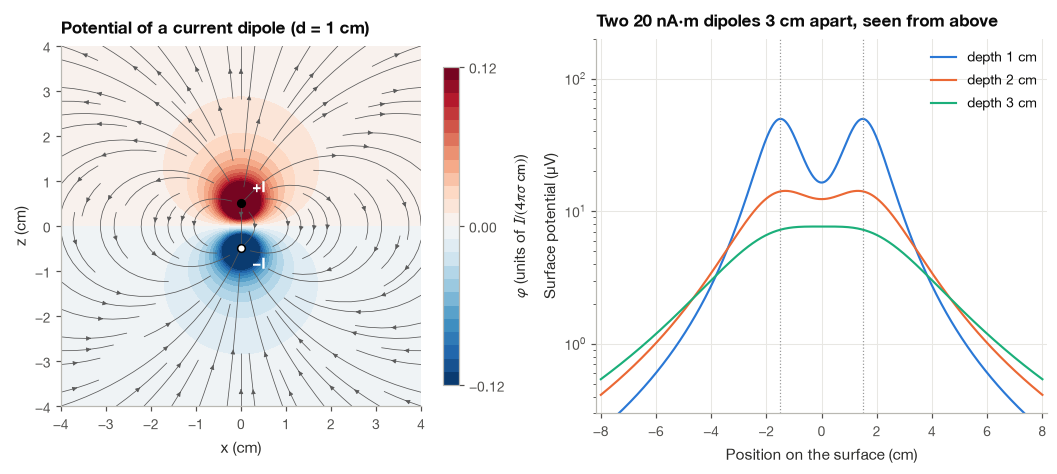

In [16]:
xg, zg = np.meshgrid(np.linspace(-4, 4, 320), np.linspace(-4, 4, 320))   # even count: no grid point on a source
pot = potential_exact(xg, zg, d=1.0)
v_lim = 0.12
Ex = (xg / np.hypot(xg, zg - 0.5) ** 3 - xg / np.hypot(xg, zg + 0.5) ** 3)
Ez = ((zg - 0.5) / np.hypot(xg, zg - 0.5) ** 3 - (zg + 0.5) / np.hypot(xg, zg + 0.5) ** 3)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
cf = ax.contourf(xg, zg, np.clip(pot, -v_lim, v_lim), levels=np.linspace(-v_lim, v_lim, 25), cmap="RdBu_r")
ax.streamplot(xg, zg, Ex, Ez, color="0.35", linewidth=0.5, density=0.9, arrowsize=0.6)
ax.plot(0, 0.5, "o", color="k", ms=5)
ax.plot(0, -0.5, "o", color="k", ms=5, mfc="white")
ax.text(0.25, 0.75, "+I", fontsize=10, color="white", fontweight="bold")
ax.text(0.25, -0.95, "−I", fontsize=10, color="white", fontweight="bold")
ax.set(xlabel="x (cm)", ylabel="z (cm)", title="Potential of a current dipole (d = 1 cm)")
ax.set_aspect("equal")
cb = fig.colorbar(cf, ax=ax, shrink=0.85, ticks=[-v_lim, 0, v_lim])
cb.set_label(r"$\varphi$ (units of $I/(4\pi\sigma\,\mathrm{cm})$)")

ax = axes[1]
x_s = np.linspace(-8, 8, 801)
p_moment, sigma_t = 20e-9, 0.33
for k, depth in enumerate([1.0, 2.0, 3.0]):
    h_m = depth / 100
    surf = sum(p_moment * h_m / (4 * np.pi * sigma_t * (((x_s - xc) / 100) ** 2 + h_m**2) ** 1.5)
               for xc in (-1.5, 1.5))
    ax.plot(x_s, surf * 1e6, color=C[k], label=f"depth {depth:.0f} cm")
for xc in (-1.5, 1.5):
    ax.axvline(xc, color="0.6", lw=0.8, ls=":")
ax.set(yscale="log", ylim=(0.3, 200), xlabel="Position on the surface (cm)", ylabel="Surface potential (µV)",
       title="Two 20 nA·m dipoles 3 cm apart, seen from above")
ax.legend(loc="upper right")
plt.show()

From a depth of 1 cm the two sources produce two clear peaks of almost 50 µV. From 3 cm they have merged into a single broad hump of about 8 µV that gives no hint of two separate generators. This spatial low-pass filtering by the volume conductor is why a scalp electrode sees the summed activity of a large area of cortex, why EEG source localization is an ill-posed problem, and why an ECG electrode on the chest records the heart as a whole rather than any particular group of cells.

(sec-1-2-7)=
## 1.2.7 The Equivalent Dipole: From the Heart to the ECG Leads

The heart is far from a single pair of point sources. During ventricular depolarization a wavefront sweeps through the muscle; ahead of it the cells are at rest, behind it they are depolarized, and along the wavefront itself current flows from the depolarized into the resting tissue. Each small element of the wavefront acts as a dipole. Seen from a distance large compared with the heart, the sum of all these dipoles is well approximated by a single **equivalent dipole**, the **heart vector** $\mathbf{p}(t)$, whose magnitude and direction change during each beat {cite:p}`malmivuo1995`. The same idea applies to the EEG, where the equivalent dipole represents the synchronized postsynaptic currents of millions of pyramidal neurons aligned perpendicular to the cortical surface {cite:p}`buzsaki2012`. Action potentials contribute little to the scalp EEG because they are brief and their fronts and tails form opposing dipoles whose fields cancel at a distance.

If the volume conductor is linear, the voltage measured by any pair of electrodes is a linear function of the dipole, and for a fixed dipole location it can be written as a dot product,

(eq-1-11)=
\begin{equation*}
v_L(t) = \mathbf{L}\cdot\mathbf{p}(t), \tag{1.11}
\end{equation*}

where the **lead vector** $\mathbf{L}$ depends only on the electrode positions and the geometry of the body. Each lead is a projection of the same rotating vector onto a different direction. In Einthoven's idealized model of the limb leads, the lead vectors of leads I, II and III lie in the frontal plane at 0°, 60° and 120° (angles measured from the patient's left toward the feet), and since the unit vectors at 0° and 120° add up to the unit vector at 60°, $(1, 0) + (-\tfrac12, \tfrac{\sqrt3}{2}) = (\tfrac12, \tfrac{\sqrt3}{2})$, (1.11) immediately gives **Einthoven's law**

(eq-1-12)=
\begin{equation*}
v_\text{II}(t) = v_\text{I}(t) + v_\text{III}(t). \tag{1.12}
\end{equation*}

I close the section with this idea, first on real data and then on a model.

### Step 1: Look at one heartbeat in two leads

Record 100 contains two simultaneous leads, a modified limb lead (MLII) and the chest lead V5. If the lead picture is right, the same beats should look different in the two leads, because the leads project the heart vector onto different directions.

In [17]:
rec = wfdb.rdrecord("../data/mitdb/100", sampfrom=360 * 20, sampto=360 * 23)
t_ecg = np.arange(rec.sig_len) / rec.fs + 20
for name, x in zip(rec.sig_name, rec.p_signal.T):
    print(f"{name:5s} peak-to-peak {np.ptp(x):.2f} mV, maximum {x.max():+.2f} mV, minimum {x.min():+.2f} mV")

MLII  peak-to-peak 1.70 mV, maximum +1.05 mV, minimum -0.65 mV
V5    peak-to-peak 1.27 mV, maximum +0.79 mV, minimum -0.47 mV


### Step 2: Build a simple frontal-plane heart vector for the QRS complex

We describe the QRS part of the heart vector by a magnitude that rises and falls as a Gaussian bump over about 100 ms and a direction that rotates steadily from the right and below (150°) round to the left and slightly above (−30°). The numbers are illustrative rather than fitted to a patient, but they give the vector a realistic size of about 1.5 mV in lead units and a mean direction inside the normal range of the electrical axis, roughly −30° to +90°.

In [18]:
t_q = np.linspace(0, 0.12, 241)                                   # s
magnitude = 1.5 * np.exp(-0.5 * ((t_q - 0.055) / 0.017) ** 2)    # mV
angle = np.deg2rad(150 - 180 * t_q / 0.12)                       # rotates from 150° to -30°
p_vec = magnitude * np.array([np.cos(angle), np.sin(angle)])     # (x: patient's left, y: feet)

lead_angles = {"I": 0, "II": 60, "III": 120}
leads = {name: np.array([np.cos(np.deg2rad(a)), np.sin(np.deg2rad(a))]) @ p_vec
         for name, a in lead_angles.items()}
print(f"Mean QRS axis : {np.rad2deg(np.arctan2(p_vec[1].sum(), p_vec[0].sum())):.0f}°")
print(f"Einthoven check, max |II - (I + III)| = {np.abs(leads['II'] - leads['I'] - leads['III']).max():.1e} mV")

Mean QRS axis : 67°
Einthoven check, max |II - (I + III)| = 3.3e-16 mV


### Step 3: Compare the projections with the real leads

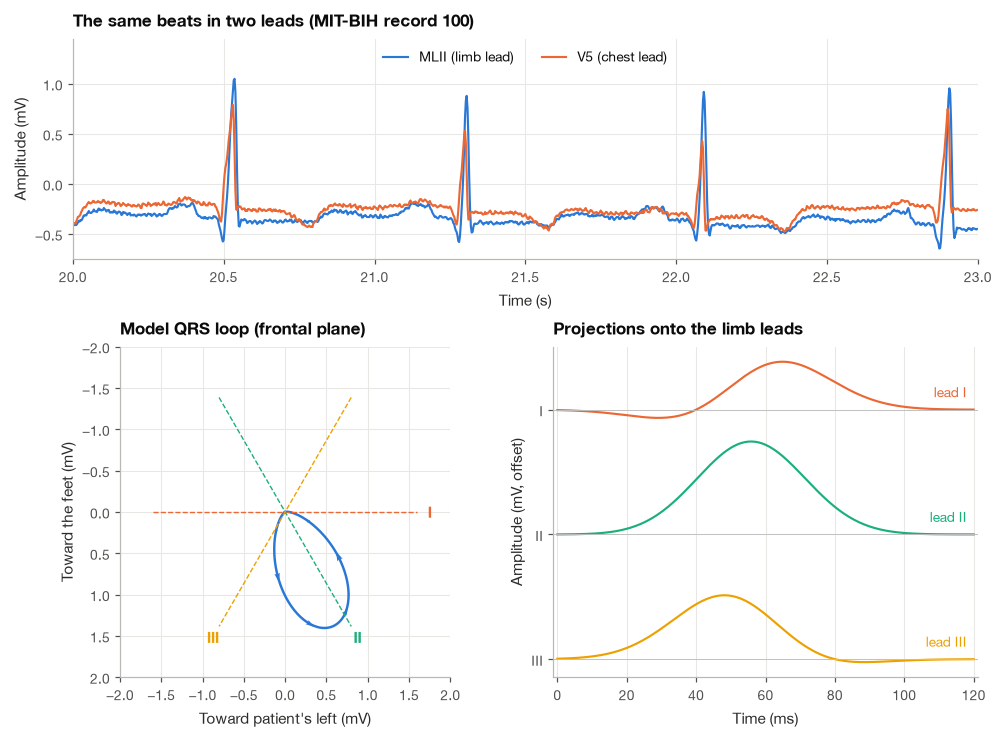

In [19]:
fig, axes = plt.subplot_mosaic([["real", "real"], ["loop", "proj"]], figsize=(9, 6.6),
                               gridspec_kw={"height_ratios": [1, 1.5]})
ax = axes["real"]
ax.plot(t_ecg, rec.p_signal[:, 0], color=C[0], label=f"{rec.sig_name[0]} (limb lead)")
ax.plot(t_ecg, rec.p_signal[:, 1], color=C[1], label=f"{rec.sig_name[1]} (chest lead)")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="The same beats in two leads (MIT-BIH record 100)",
       xlim=(20, 23), ylim=(-0.75, 1.45))
ax.legend(loc="upper center", ncols=2)

ax = axes["loop"]
ax.plot(p_vec[0], p_vec[1], color=C[0], lw=1.6)
idx = np.arange(20, 220, 25)
ax.quiver(p_vec[0, idx], p_vec[1, idx], np.gradient(p_vec[0])[idx], np.gradient(p_vec[1])[idx],
          color=C[0], angles="xy", scale_units="xy", scale=0.25, width=0.006)
for k, (name, a) in enumerate(lead_angles.items()):
    u = np.array([np.cos(np.deg2rad(a)), np.sin(np.deg2rad(a))])
    ax.plot([-1.6 * u[0], 1.6 * u[0]], [-1.6 * u[1], 1.6 * u[1]], color=C[k + 1], lw=0.9, ls="--")
    ax.text(1.75 * u[0], 1.75 * u[1], name, color=C[k + 1], ha="center", va="center", fontweight="bold")
ax.set(xlim=(-2, 2), ylim=(2, -2), xlabel="Toward patient's left (mV)", ylabel="Toward the feet (mV)",
       title="Model QRS loop (frontal plane)")
ax.set_aspect("equal")

ax = axes["proj"]
for k, (name, v) in enumerate(leads.items()):
    ax.plot(1000 * t_q, v - 2.0 * k, color=C[k + 1])
    ax.axhline(-2.0 * k, color="0.75", lw=0.6)
    ax.text(118, -2.0 * k + 0.2, f"lead {name}", color=C[k + 1], ha="right", fontsize=9)
ax.set(xlabel="Time (ms)", ylabel="Amplitude (mV, offset)", title="Projections onto the limb leads",
       yticks=[0, -2, -4], yticklabels=["I", "II", "III"])
plt.show()

The real recording shows the lead effect clearly. In MLII the QRS complex is a tall, narrow upward spike; in V5 the same beats are smaller and differently shaped, because V5 looks at the heart vector from the front and side of the chest rather than along the axis of the limbs. The model reproduces the mechanism in its simplest form: one rotating vector, three projections and three different QRS shapes, from a small negative deflection followed by a positive one in lead I to the large upright complex in lead II, which lies closest to the mean axis. Einthoven's law holds to machine precision because it is a statement about vector geometry, not about the heart. [Section 11.1](../ch17_ecg/01_cardiac_electrophysiology.ipynb) develops the cardiac side of this picture in detail, and [Section 11.2](../ch17_ecg/02_recording_the_ecg.ipynb) the standard 12-lead system.

## Summary

Bioelectric signals start with ion concentration differences maintained by membrane pumps. When a membrane is permeable to a single ion, diffusion and electrical drift balance at the Nernst potential $E = (RT/zF)\ln(c_o/c_i)$, which we derived from the Nernst–Planck equation by setting the flux to zero and integrating across the membrane. With several permeant ions, the resting potential is the zero-current point given by the Goldman–Hodgkin–Katz equation, about −70 mV for typical permeabilities and strongly dependent on extracellular potassium. The Hodgkin–Huxley model explains the action potential through fast sodium activation followed by slower sodium inactivation and potassium activation; integrated numerically, it reproduces the all-or-none threshold (about 6.9 µA/cm² for a 1-ms pulse) and the absolute and relative refractory periods.

Outside the cells, currents spread through a volume conductor. A point source produces a potential $I/(4\pi\sigma r)$, a source–sink pair a dipole potential $\mathbf{p}\cdot\mathbf{r}/(4\pi\sigma r^3)$ that falls as $1/r^2$, and a source at depth $h$ appears on the surface as a hump of width about $1.5h$ and height proportional to $1/h^2$. That is why surface signals are small and spatially smooth. Summarizing the heart's activity as a single rotating dipole, each ECG lead becomes a projection of the heart vector, which explains why leads differ and why Einthoven's law holds. The next section follows the signal out of the body and into the computer.

## Exercises

1. Compute the Nernst potentials of K⁺ and Ca²⁺ at 20 °C and at 37 °C using the concentrations of Section 1.2.1. By what percentage does the temperature change alter each potential?
2. Starting from the GHK equation (1.4), show that it reduces to the Nernst equation for potassium when $P_\text{Na} = P_\text{Cl} = 0$. Then compute the resting potential for $P_K : P_\text{Na} : P_\text{Cl} = 1 : 0.04 : 0.45$ when $[Na]_o$ falls from 145 to 120 mM (hyponatremia). Is the membrane more or less sensitive to sodium than to potassium, and why?
3. Using `hh_rk4`, find the threshold amplitude for pulse durations of 0.1, 0.2, 0.5, 1, 2 and 5 ms and plot this strength–duration curve. Which pulse duration requires the least *charge* (amplitude times duration) to fire the axon?
4. Inject a constant current, starting at $t = 5$ ms and lasting 200 ms, with amplitudes from 0 to 30 µA/cm². Find the smallest current that produces repetitive firing and plot the firing rate against the current. What happens just above that minimum?
5. A dipole at depth $h$ points *parallel* to the surface (a tangential dipole, as in a sulcus wall). Using (1.9), derive the surface potential $\varphi(x)$ along the dipole direction, show that it is zero directly above the dipole, and prove that its extremes lie at $x = \pm h/\sqrt{2}$.
6. The augmented limb leads have lead vectors at −150° (aVR), −30° (aVL) and 90° (aVF). Show using vector geometry that $v_\text{aVR} + v_\text{aVL} + v_\text{aVF} = 0$ for any heart vector, and verify it numerically with the model loop of Section 1.2.7.

## Further Reading

{cite:t}`plonsey2007` derive the Nernst, Goldman and Hodgkin–Huxley equations with more physical detail than I have space for here, and treat volume conduction quantitatively. {cite:t}`malmivuo1995` is the classic reference on bioelectric and biomagnetic fields, lead vectors and the electrical models of the heart and brain; it is freely available online. The original papers by {cite:t}`goldman1943` and {cite:t}`hodgkin1952` are still very readable, and {cite:t}`buzsaki2012` review how extracellular fields such as the EEG and the local field potential arise from neuronal currents.